In [1]:

# Q1. Text preprocessing and word frequency distribution

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# My paragraph about Artificial Intelligence
text = """Artificial intelligence is changing the world.
It helps people solve problems and learn new things.
AI is used in healthcare, education, and business.
Machine learning helps computers find patterns in data.
I enjoy learning AI because it makes technology more useful.
In the future, AI may help us in many different ways."""

# 1. Convert text to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Clean Text:")
print(clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:")
print(words)

print("\nSentence Tokens:")
print(sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():")
print(clean_text.split())

print("\nUsing word_tokenize():")
print(word_tokenize(text.lower()))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after removing stopwords:")
print(filtered_words)

# 5. Display word frequency distribution
frequency = FreqDist(filtered_words)

print("\nWord Frequency:")
print(frequency)
print("\nMost Common Words:")
print(frequency.most_common())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Clean Text:
artificial intelligence is changing the world
it helps people solve problems and learn new things
ai is used in healthcare education and business
machine learning helps computers find patterns in data
i enjoy learning ai because it makes technology more useful
in the future ai may help us in many different ways

Word Tokens:
['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'learn', 'new', 'things', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'machine', 'learning', 'helps', 'computers', 'find', 'patterns', 'in', 'data', 'i', 'enjoy', 'learning', 'ai', 'because', 'it', 'makes', 'technology', 'more', 'useful', 'in', 'the', 'future', 'ai', 'may', 'help', 'us', 'in', 'many', 'different', 'ways']

Sentence Tokens:
['Artificial intelligence is changing the world.', 'It helps people solve problems and learn new things.', 'AI is used in healthcare, education, and business.', 'Machine lea

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:

# Q2. Stemming and lemmatization using the same paragraph from Q1

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is changing the world.
It helps people solve problems and learn new things.
AI is used in healthcare, education, and business.
Machine learning helps computers find patterns in data.
I enjoy learning AI because it makes technology more useful.
In the future, AI may help us in many different ways."""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("All Words:")
print(words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\nWords after removing stopwords:")
print(filtered_words)

# 3. Perform stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\nStemmed Words:")
print(stemmed_words)

# 4. Perform lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]
print("\nLemmatized Words:")
print(lemmatized_words)

# 5. Compare the results
print("\nComparison:")
for i in range(len(filtered_words)):
    print(filtered_words[i], "->", stemmed_words[i],
          "->", lemmatized_words[i])


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All Words:
['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'learn', 'new', 'things', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'machine', 'learning', 'helps', 'computers', 'find', 'patterns', 'in', 'data', 'i', 'enjoy', 'learning', 'ai', 'because', 'it', 'makes', 'technology', 'more', 'useful', 'in', 'the', 'future', 'ai', 'may', 'help', 'us', 'in', 'many', 'different', 'ways']

Words after removing stopwords:
['artificial', 'intelligence', 'changing', 'world', 'helps', 'people', 'solve', 'problems', 'learn', 'new', 'things', 'ai', 'used', 'healthcare', 'education', 'business', 'machine', 'learning', 'helps', 'computers', 'find', 'patterns', 'data', 'enjoy', 'learning', 'ai', 'makes', 'technology', 'useful', 'future', 'ai', 'may', 'help', 'us', 'many', 'different', 'ways']

Stemmed Words:
['artifici', 'intellig', 'chang', 'world', 'help', 'peopl', 'solv', 'problem', 'learn', 'new', 'thin

In [3]:

# Q3. Bag of Words and TF-IDF keyword extraction

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three original short texts
texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning uses data to train intelligent computer systems.",
    "Artificial intelligence and machine learning are useful technologies."
]

# 1. Bag of Words representation
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(bow_matrix.toarray())
print("\nVocabulary:")
print(count_vectorizer.get_feature_names_out())

# 2. Calculate TF-IDF scores
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

# 3. Find the top 3 keywords from each text
features = tfidf_vectorizer.get_feature_names_out()

for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray()[0]
    top_indices = scores.argsort()[::-1][:3]

    print("\nText", i + 1, ":", texts[i])
    print("Top 3 keywords:")

    for index in top_indices:
        print(features[index], ":", round(scores[index], 3))


Bag of Words:
[[1 0 1 0 1 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 1 0 1]
 [1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 0]]

Vocabulary:
['and' 'are' 'artificial' 'computer' 'computers' 'data' 'helps'
 'intelligence' 'intelligent' 'learn' 'learning' 'machine' 'problems'
 'solve' 'systems' 'technologies' 'to' 'train' 'useful' 'uses']

TF-IDF Matrix:
[[0.29304799 0.         0.29304799 0.         0.38532289 0.
  0.38532289 0.29304799 0.         0.38532289 0.         0.
  0.38532289 0.38532289 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.35013871 0.         0.35013871
  0.         0.         0.35013871 0.         0.26628951 0.26628951
  0.         0.         0.35013871 0.         0.35013871 0.35013871
  0.         0.35013871]
 [0.31331607 0.41197298 0.31331607 0.         0.         0.
  0.         0.31331607 0.         0.         0.31331607 0.31331607
  0.         0.         0.         0.41197298 0.         0.
  0.411

In [4]:

# Q4. Compare two technologies using similarity measures

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Technology 1: Artificial Intelligence
text1 = """Artificial intelligence helps computers learn from data.
It can solve problems and make predictions.
AI is used in healthcare and education.
Machine learning is an important part of artificial intelligence."""

# Technology 2: Blockchain
text2 = """Blockchain stores data in a secure digital ledger.
It helps maintain transparent and trusted transactions.
Blockchain is used in finance and digital currencies.
It can improve data security and record keeping."""

# 1. Preprocess and tokenize both texts
words1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
words2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

set1 = set(words1)
set2 = set(words2)

print("AI Words:")
print(words1)

print("\nBlockchain Words:")
print(words2)

# 2(a). Calculate Jaccard Similarity
intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:")
print(intersection)

print("\nJaccard Similarity:", round(jaccard, 3))

# 2(b). Calculate Cosine Similarity using TF-IDF
texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 3))

# 2(c). Compare the two measures
print("\nConclusion:")

if cosine > jaccard:
    print("Cosine similarity shows more similarity between the texts.")
elif jaccard > cosine:
    print("Jaccard similarity shows more similarity between the texts.")
else:
    print("Both measures give the same similarity score.")


AI Words:
['artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'it', 'can', 'solve', 'problems', 'and', 'make', 'predictions', 'ai', 'is', 'used', 'in', 'healthcare', 'and', 'education', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'artificial', 'intelligence']

Blockchain Words:
['blockchain', 'stores', 'data', 'in', 'a', 'secure', 'digital', 'ledger', 'it', 'helps', 'maintain', 'transparent', 'and', 'trusted', 'transactions', 'blockchain', 'is', 'used', 'in', 'finance', 'and', 'digital', 'currencies', 'it', 'can', 'improve', 'data', 'security', 'and', 'record', 'keeping']

Common Words:
{'used', 'data', 'is', 'can', 'it', 'helps', 'and', 'in'}

Jaccard Similarity: 0.19
Cosine Similarity: 0.266

Conclusion:
Cosine similarity shows more similarity between the texts.


In [5]:

# Q5. Install the libraries required for sentiment analysis
!pip install textblob wordcloud



Review: This phone has an excellent camera and great battery life.
Polarity: 0.9
Subjectivity: 0.88
Sentiment: Positive

Review: I love this product because it is fast and easy to use.
Polarity: 0.38
Subjectivity: 0.68
Sentiment: Positive

Review: The phone is terrible and the battery drains very quickly.
Polarity: -0.28
Subjectivity: 0.82
Sentiment: Negative

Review: The product is bad and the service was disappointing.
Polarity: -0.65
Subjectivity: 0.68
Sentiment: Negative

Review: The phone is okay and has a normal display.
Polarity: 0.33
Subjectivity: 0.57
Sentiment: Positive


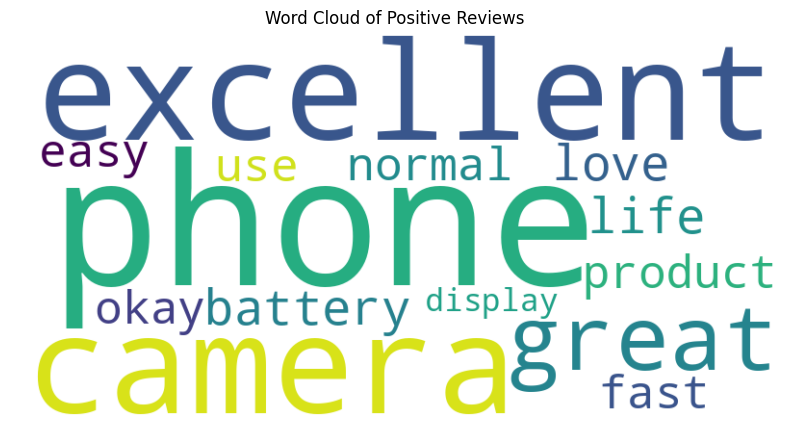

In [6]:

# Q5. Sentiment analysis and word cloud of positive reviews

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Sample product reviews
reviews = [
    "This phone has an excellent camera and great battery life.",
    "I love this product because it is fast and easy to use.",
    "The phone is terrible and the battery drains very quickly.",
    "The product is bad and the service was disappointing.",
    "The phone is okay and has a normal display."
]

positive_reviews = []

# 1. Find polarity and subjectivity
for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    # 2. Classify each review
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)

# 3. Create a word cloud from positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews found.")
